# Lab 2 · Part II: Convolutional Neural Networks and Image Classification

We train a small CNN on **CIFAR-10** (60,000 colour images, 10 classes) with cross-entropy and SGD with momentum,
and see how the learning rate, batch size and a learning-rate schedule change training.

The whole dataset fits in memory (~600 MB as float32), so we load it once as tensors on the GPU (or MPS/CPU) and
build batches by indexing, without a `DataLoader`. Seeds are fixed, but GPU kernels aren't bit-exact, so the last
digit may change between runs.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets
from sklearn.metrics import confusion_matrix

RNG_SEED = 0
dev = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
torch.manual_seed(RNG_SEED)
torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False
pd.options.display.float_format = "{:.4g}".format
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("running on", dev)

running on cuda


## 1. Loading, splitting and normalizing CIFAR-10

`torchvision` gives 50,000 training and 10,000 test images. We set aside 5,000 training images (fixed seed) as a
**validation** set for watching overfitting and comparing hyperparameters, so the **test** set is only used for the
reported accuracy. Each colour channel is scaled to mean 0 and std 1 using the 45,000 training images only, so
nothing leaks in from validation or test.

In [2]:
cifar_train = datasets.CIFAR10("data", train=True, download=True)
cifar_test = datasets.CIFAR10("data", train=False, download=True)
LABELS = cifar_train.classes

def as_float(imgs):  # uint8 NHWC -> float32 NCHW in [0, 1]
    return torch.from_numpy(imgs).permute(0, 3, 1, 2).float().div(255)

X_full, y_full = as_float(cifar_train.data), torch.tensor(cifar_train.targets)
X_te, y_te = as_float(cifar_test.data), torch.tensor(cifar_test.targets)

shuffle = torch.randperm(len(X_full), generator=torch.Generator().manual_seed(RNG_SEED))
X_tr, y_tr = X_full[shuffle[:45_000]], y_full[shuffle[:45_000]]
X_va, y_va = X_full[shuffle[45_000:]], y_full[shuffle[45_000:]]

mu = X_tr.mean(dim=(0, 2, 3), keepdim=True)
sd = X_tr.std(dim=(0, 2, 3), keepdim=True)
print("channel means (R, G, B):", mu.flatten().numpy().round(4))
print("channel stds  (R, G, B):", sd.flatten().numpy().round(4))

X_te_raw = X_te  # unnormalized copy, only for plotting
standardize = lambda X: ((X - mu) / sd).to(dev)
X_tr, X_va, X_te = map(standardize, (X_tr, X_va, X_te))
y_tr, y_va, y_te = y_tr.to(dev), y_va.to(dev), y_te.to(dev)
print(f"shapes: train {tuple(X_tr.shape)} | val {tuple(X_va.shape)} | test {tuple(X_te.shape)}")
print("train set after standardizing: mean", X_tr.mean(dim=(0, 2, 3)).cpu().numpy().round(3),
      "| std", X_tr.std(dim=(0, 2, 3)).cpu().numpy().round(3))

channel means (R, G, B): [0.4912 0.482  0.4464]
channel stds  (R, G, B): [0.2472 0.2436 0.2617]


shapes: train (45000, 3, 32, 32) | val (5000, 3, 32, 32) | test (10000, 3, 32, 32)
train set after standardizing: mean [0. 0. 0.] | std [1. 1. 1.]


## 2. Looking at the data

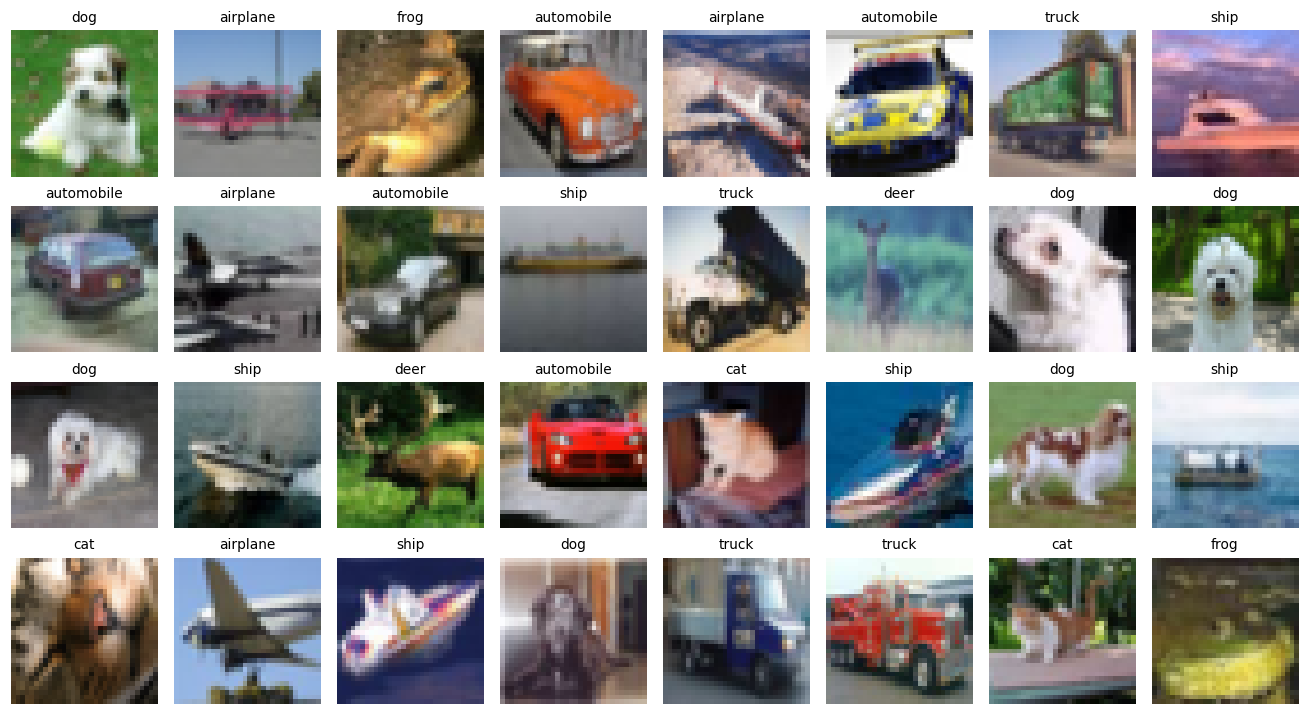

one image: 3 channels, 32x32 pixels
10 classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck
input space: 3*32*32 = 3072 dimensions
training images per class: [4518, 4492, 4506, 4496, 4468, 4493, 4498, 4494, 4502, 4533]


In [3]:
pick = torch.randperm(len(X_te_raw), generator=torch.Generator().manual_seed(1))[:32]
fig, axs = plt.subplots(4, 8, figsize=(12, 6.6))
for ax, k in zip(axs.flat, pick):
    ax.imshow(X_te_raw[k].permute(1, 2, 0).numpy())
    ax.set_title(LABELS[y_te[k]], fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

n_ch, h, w = X_tr.shape[1:]
print(f"one image: {n_ch} channels, {h}x{w} pixels")
print(f"{len(LABELS)} classes:", ", ".join(LABELS))
print(f"input space: {n_ch}*{h}*{w} = {n_ch * h * w} dimensions")
print("training images per class:", torch.bincount(y_tr).tolist())

**Observations.** Each image is 3×32×32 (RGB, 32×32 pixels), and there are 10 classes (airplane, automobile, bird,
cat, deer, dog, frog, horse, ship, truck), so the input space has $3\cdot32\cdot32 = 3072$ dimensions. The classes are
balanced (4,468-4,533 training images each), so plain accuracy is a fair metric. At this resolution some classes are
hard to tell apart even for us (cat/dog, deer/horse). After normalization the training channels have mean 0 and std 1
by construction; validation and test are only approximately standardized.

## 3. CNN architecture

```
input 3×32×32 → Conv(3→32, 3×3, pad 1) → ReLU → MaxPool 2×2 → Conv(32→64, 3×3, pad 1) → ReLU → MaxPool 2×2
              → Flatten (64·8·8 = 4096) → FC(4096→128) → ReLU → FC(128→10) → softmax
```

With padding 1 the convolutions keep the size, so only the pooling layers halve it (32 → 16 → 8).

**Where the softmax is.** `nn.CrossEntropyLoss` already applies log-softmax and then the negative log-likelihood, so it
wants raw **logits**. Putting a softmax in `forward()` as well would apply it twice and flatten the gradients. So
`forward()` returns logits for training, and `predict_proba()` applies the softmax output layer at inference.

In [4]:
class SmallCNN(nn.Module):
    def __init__(self, n_out=10):
        super().__init__()
        self.conv_a = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv_b = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.dense = nn.Linear(64 * 8 * 8, 128)
        self.head = nn.Linear(128, n_out)

    def forward(self, x):  # logits
        x = self.pool(F.relu(self.conv_a(x)))
        x = self.pool(F.relu(self.conv_b(x)))
        return self.head(F.relu(self.dense(x.flatten(1))))

    @torch.no_grad()
    def predict_proba(self, x):  # softmax output layer, for inference
        return F.softmax(self(x), dim=1)

def layer_params(net):
    t = pd.DataFrame([{"layer": n, "weights": m.weight.numel(), "biases": m.bias.numel()}
                      for n, m in net.named_children() if hasattr(m, "weight")]).set_index("layer")
    t["total"] = t.weights + t.biases
    t.loc["all layers"] = t.sum()
    return t.astype(int)

torch.manual_seed(RNG_SEED)
cnn = SmallCNN().to(dev)
print(cnn)
assert layer_params(cnn).loc["all layers", "total"] == sum(p.numel() for p in cnn.parameters())
layer_params(cnn)

SmallCNN(
  (conv_a): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv_b): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dense): Linear(in_features=4096, out_features=128, bias=True)
  (head): Linear(in_features=128, out_features=10, bias=True)
)


,weights,biases,total
layer,,,
conv_a,864,32,896
conv_b,18432,64,18496
dense,524288,128,524416
head,1280,10,1290
all layers,544864,234,545098


**Observations.** The network has **545,098 parameters**, and 96% of them (524,416) are in the fully connected layer:
going from $64\times8\times8 = 4096$ features to 128 units costs $4096\cdot128$ weights. The two convolutions have only
19,392 parameters together (3.6%) because each filter is reused at every position, even though they do most of the
computation. A big dense layer on top of a few conv features tends to overfit, and we'll see that below.

## 4. Loss and optimizer

Loss: `nn.CrossEntropyLoss` (batch mean). Optimizer: `torch.optim.SGD` with **learning rate 0.01** and **momentum 0.9**.
Momentum keeps a running average of the gradients, which smooths out mini-batch noise and speeds things up along
directions that stay consistent. The effective step is about $\eta/(1-0.9) = 10\eta$, so 0.01 behaves roughly like 0.1
in plain SGD. That's a common, fairly safe choice for a small CNN without batch norm: 0.1 is usually too aggressive here
and 0.001 too slow for ~15 epochs. Step 6 checks this.

## 5. Training

`train_cnn()` reshuffles the mini-batches every epoch and, after each epoch, records loss and accuracy on the train,
validation and test sets. These are computed in `eval` mode on the full sets, so the train numbers aren't noisy
running averages. Batch size 64, **15 epochs**.

In [5]:
criterion = nn.CrossEntropyLoss()

@torch.no_grad()
def eval_split(net, X, y, chunk=5000):
    net.eval()
    tot_loss, hits = 0.0, 0
    for s in range(0, len(X), chunk):
        z = net(X[s:s + chunk])
        tot_loss += F.cross_entropy(z, y[s:s + chunk], reduction="sum").item()
        hits += (z.argmax(1) == y[s:s + chunk]).sum().item()
    return tot_loss / len(X), hits / len(X)

SPLITS = {"train": (X_tr, y_tr), "val": (X_va, y_va), "test": (X_te, y_te)}

def train_cnn(epochs=15, lr=0.01, momentum=0.9, bs=64, schedule=None, seed=RNG_SEED,
              track=("train", "val", "test"), show=False):
    torch.manual_seed(seed)
    net = SmallCNN().to(dev)
    opt = torch.optim.SGD(net.parameters(), lr=lr, momentum=momentum)
    sched = None
    if schedule == "cosine":  # per step, from lr down to 0 over the whole run
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * -(-len(X_tr) // bs))
    gen = torch.Generator().manual_seed(seed)
    rows, start = [], time.time()
    for ep in range(1, epochs + 1):
        net.train()
        order = torch.randperm(len(X_tr), generator=gen).to(dev)
        for s in range(0, len(order), bs):
            b = order[s:s + bs]
            loss = criterion(net(X_tr[b]), y_tr[b])
            opt.zero_grad(); loss.backward(); opt.step()
            if sched: sched.step()
        row = {"epoch": ep, "seconds": time.time() - start}
        for k in track:
            row[f"loss_{k}"], row[f"acc_{k}"] = eval_split(net, *SPLITS[k])
        rows.append(row)
        if show:
            print(f"ep {ep:2d}  " + "  ".join(f"{k}: loss {row['loss_' + k]:.3f}, acc {row['acc_' + k]:.2%}" for k in track))
    return net, pd.DataFrame(rows).set_index("epoch")

t_start = time.time()
cnn, curves = train_cnn(epochs=15, show=True)
print(f"\ntotal training time: {time.time() - t_start:.0f} s")

ep  1  train: loss 1.073, acc 62.23%  val: loss 1.159, acc 59.00%  test: loss 1.124, acc 61.17%


ep  2  train: loss 0.834, acc 70.97%  val: loss 0.973, acc 65.84%  test: loss 0.954, acc 66.54%


ep  3  train: loss 0.707, acc 75.78%  val: loss 0.934, acc 68.40%  test: loss 0.912, acc 69.26%


ep  4  train: loss 0.531, acc 81.75%  val: loss 0.873, acc 70.44%  test: loss 0.845, acc 71.50%


ep  5  train: loss 0.453, acc 84.48%  val: loss 0.906, acc 70.60%  test: loss 0.889, acc 70.59%


ep  6  train: loss 0.294, acc 90.26%  val: loss 0.942, acc 71.70%  test: loss 0.924, acc 71.55%


... (5 outputs left out)

ep 12  train: loss 0.077, acc 97.42%  val: loss 1.697, acc 70.20%  test: loss 1.645, acc 70.65%


ep 13  train: loss 0.077, acc 97.45%  val: loss 1.821, acc 71.00%  test: loss 1.772, acc 70.83%


ep 14  train: loss 0.060, acc 97.98%  val: loss 1.812, acc 70.90%  test: loss 1.798, acc 71.48%


ep 15  train: loss 0.116, acc 96.18%  val: loss 2.116, acc 68.94%  test: loss 2.030, acc 69.92%

total training time: 24 s


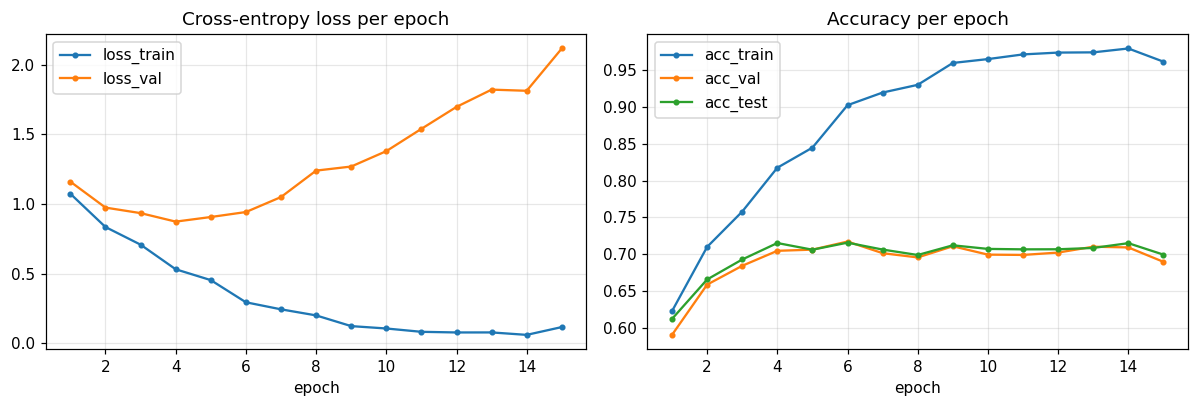

val loss is lowest at epoch 4 (0.873)
after epoch 15: train acc 96.18%, val acc 68.94%, test acc 69.92%


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
curves[["loss_train", "loss_val"]].plot(ax=axs[0], marker="o", ms=3, title="Cross-entropy loss per epoch")
curves[["acc_train", "acc_val", "acc_test"]].plot(ax=axs[1], marker="o", ms=3, title="Accuracy per epoch")
for a in axs: a.set_xlabel("epoch")
plt.tight_layout(); plt.show()

e_min = curves.loss_val.idxmin()
last = curves.iloc[-1]
print(f"val loss is lowest at epoch {e_min} ({curves.loss_val[e_min]:.3f})")
print(f"after epoch {len(curves)}: train acc {last.acc_train:.2%}, val acc {last.acc_val:.2%}, test acc {last.acc_test:.2%}")

softmax rows sum to 1: True | test accuracy 69.92%


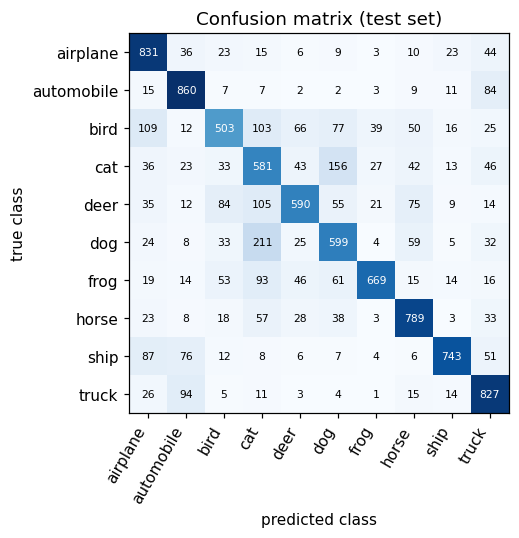

bird         0.503
cat          0.581
deer          0.59
dog          0.599
frog         0.669
ship         0.743
horse        0.789
truck        0.827
airplane     0.831
automobile    0.86

most common mistake: dog predicted as cat (211 images)


In [7]:
with torch.no_grad():
    cnn.eval()
    probs = torch.cat([cnn.predict_proba(X_te[s:s + 5000]) for s in range(0, len(X_te), 5000)])
y_pred = probs.argmax(1).cpu().numpy()
y_true = y_te.cpu().numpy()
print("softmax rows sum to 1:", torch.allclose(probs.sum(1), torch.ones(len(probs), device=dev), atol=1e-4),
      f"| test accuracy {np.mean(y_pred == y_true):.2%}")

cmat = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cmat, cmap="Blues")
ax.set(xticks=range(10), yticks=range(10), xlabel="predicted class", ylabel="true class", title="Confusion matrix (test set)")
ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_yticklabels(LABELS); ax.grid(False)
for r in range(10):
    for c in range(10):
        ax.text(c, r, cmat[r, c], ha="center", va="center", fontsize=7, color="white" if cmat[r, c] > cmat.max() / 2 else "black")
plt.tight_layout(); plt.show()
recall = pd.Series(cmat.diagonal() / cmat.sum(1), index=LABELS, name="per-class test accuracy").sort_values()
print(recall.round(3).to_string())
mistakes = cmat - np.diag(cmat.diagonal())
r, c = np.unravel_index(mistakes.argmax(), mistakes.shape)
print(f"\nmost common mistake: {LABELS[r]} predicted as {LABELS[c]} ({mistakes[r, c]} images)")

**Observations.**
- **Overfitting after ~4 epochs.** The train loss keeps falling (to ~0.06-0.12, 96-98% train accuracy), but the validation
  loss bottoms out at epoch 4 (0.87) and then climbs to 2.12 by epoch 15. The model first learns general features and then
  starts memorizing the 45k training images (545k parameters, no regularization or augmentation).
- **Accuracy hides it.** Validation and test accuracy stay at ≈ 69-72% from epoch 4 on, while the loss more than doubles.
  The net gets more and more confident about its mistakes (which cross-entropy punishes hard), but its argmax predictions
  barely change. Stopping around epoch 4-6 would give the best loss at about the same accuracy.
- **Final test accuracy: 69.9%** (train 96.2%, val 68.9%; chance is 10%). Validation and test agree within about a
  point, so the validation set is a good stand-in for the test set. With a constant learning rate the accuracy moves
  by 1-2 points from epoch to epoch (epoch 14 had 71.5% test), so the differences between the last epochs are noise.
- **Per class:** automobile (86%), airplane and truck (83%) are easiest. Bird (50%), cat (58%), deer (59%) and dog (60%)
  are hardest, and the most common mistake is dog → cat (211 test images). Animals mostly get mixed up with other
  animals and vehicles with other vehicles (automobile ↔ truck, ship → airplane); birds are also often called airplanes,
  probably because of the sky background.

## 6. Learning rate, batch size and schedule

A small grid, 8 epochs per run, same initialization seed, momentum 0.9, compared on the **validation** set (the test set
stays out of it): learning rate ∈ {0.001, 0.01, 0.1} at batch 64, batch size ∈ {32, 64, 256} at lr 0.01, and a cosine
schedule (lr decays from 0.01 to 0 over the run, per step). Note that with a fixed number of epochs a smaller batch
means more updates: 704 / 1407 steps per epoch for batch 64 / 32, but only 176 for batch 256.

In [8]:
SHORT = 8
grid = {
    "lr 0.001 | bs 64": dict(lr=0.001, bs=64),
    "lr 0.01 | bs 64": dict(lr=0.01, bs=64),
    "lr 0.1 | bs 64": dict(lr=0.1, bs=64),
    "lr 0.01 | bs 32": dict(lr=0.01, bs=32),
    "lr 0.01 | bs 256": dict(lr=0.01, bs=256),
    "lr 0.01 | bs 64 | cosine": dict(lr=0.01, bs=64, schedule="cosine"),
}
runs = {}
for label, kw in grid.items():
    _, runs[label] = train_cnn(epochs=SHORT, track=("train", "val"), **kw)
    print(f"{label:26s} final val acc {runs[label].acc_val.iloc[-1]:.2%}  [{runs[label].seconds.iloc[-1]:.0f} s]")

lr 0.001 | bs 64           final val acc 64.58%  [11 s]


lr 0.01 | bs 64            final val acc 69.54%  [12 s]


lr 0.1 | bs 64             final val acc 43.96%  [11 s]


lr 0.01 | bs 32            final val acc 68.28%  [20 s]


lr 0.01 | bs 256           final val acc 69.92%  [3 s]


lr 0.01 | bs 64 | cosine   final val acc 74.12%  [12 s]


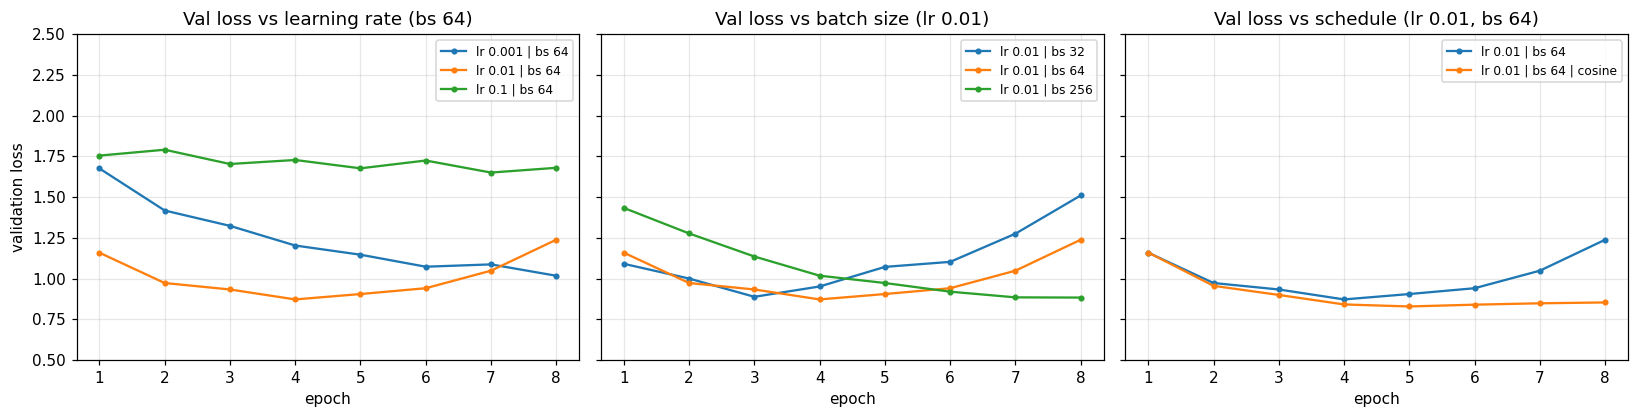

,train loss (end),val loss (end),val loss (min),epoch of min,train acc (end),val acc (end),val acc (best),seconds
lr 0.001 | bs 64,0.9013,1.018,1.018,8,0.6877,0.6458,0.6458,10.74
lr 0.01 | bs 64,0.1994,1.239,0.8728,4,0.9303,0.6954,0.717,11.89
lr 0.1 | bs 64,1.409,1.68,1.651,7,0.5172,0.4396,0.44,10.76
lr 0.01 | bs 32,0.1926,1.511,0.8889,3,0.9325,0.6828,0.6966,19.61
lr 0.01 | bs 256,0.6059,0.8842,0.8842,8,0.7902,0.6992,0.6992,3.38
lr 0.01 | bs 64 | cosine,0.239,0.8543,0.8296,5,0.9317,0.7412,0.7416,11.9


In [9]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
panels = [("learning rate (bs 64)", ["lr 0.001 | bs 64", "lr 0.01 | bs 64", "lr 0.1 | bs 64"]),
          ("batch size (lr 0.01)", ["lr 0.01 | bs 32", "lr 0.01 | bs 64", "lr 0.01 | bs 256"]),
          ("schedule (lr 0.01, bs 64)", ["lr 0.01 | bs 64", "lr 0.01 | bs 64 | cosine"])]
for a, (title, labels) in zip(axs, panels):
    for lab in labels:
        a.plot(runs[lab].index, runs[lab].loss_val, marker="o", ms=3, label=lab)
    a.set(title=f"Val loss vs {title}", xlabel="epoch"); a.legend(fontsize=8)
axs[0].set_ylabel("validation loss"); axs[0].set_ylim(0.5, 2.5)
plt.tight_layout(); plt.show()

overview = pd.DataFrame({lab: {"train loss (end)": c.loss_train.iloc[-1], "val loss (end)": c.loss_val.iloc[-1],
                               "val loss (min)": c.loss_val.min(), "epoch of min": c.loss_val.idxmin(),
                               "train acc (end)": c.acc_train.iloc[-1], "val acc (end)": c.acc_val.iloc[-1],
                               "val acc (best)": c.acc_val.max(), "seconds": c.seconds.iloc[-1]}
                         for lab, c in runs.items()}).T
overview

**Observations** (8 epochs each, one seed; with 5,000 validation images one standard error of the accuracy is ≈ 0.65
points, so differences of a point or less are noise).
- **Learning rate.** 0.001 is too low: after 8 epochs the loss is still going down (val loss 1.02, train accuracy only
  69%), so it underfits in this budget. 0.01 learns fast (val loss 0.87 at epoch 4) but then overfits (1.24 at epoch 8).
  0.1 with momentum 0.9 is too high: the val loss never gets below 1.65, train accuracy only reaches 52%, and training is
  erratic. It is right at the edge: in an earlier trial run with non-deterministic kernels it diverged to NaN. So the usual
  picture: too low is slow, too high is unstable, and ~0.01 is the sweet spot here.
- **Batch size** (lr 0.01). The best validation loss is almost the same for 32, 64 and 256 (0.87-0.89), but it is reached
  at epoch 3, 4 and 8. With a fixed number of epochs a smaller batch gets more updates (1407 / 704 / 176 per epoch) with
  noisier gradients (noise ∝ $1/\sqrt{B}$). So batch 32 fits and overfits fastest (final val loss 1.51), while batch 256
  is still improving at epoch 8 (train accuracy 79%). Batch 256 is also ~6× faster per epoch on the GPU than batch 32
  (3 s vs 20 s), because a big batch costs the GPU almost nothing extra; for wall-clock time, a large batch with a larger
  learning rate is attractive. Final validation accuracies are close (68.3-69.9%), within about two standard errors.
- **Schedule.** Cosine decay from 0.01 to 0 gives the best result of the whole study: val loss 0.83 at epoch 5 and 0.85
  at the end (vs 1.24 with a constant lr), and **74.1% val accuracy vs 69.5%**. The high rate early on makes fast
  progress, and the small rate at the end lets the weights settle instead of bouncing around the minimum, so the loss
  doesn't climb. Train accuracy is the same (93%), so the gain comes from a better solution, not from fitting less.
  (We didn't redo the 15-epoch run with it, to keep the test set out of the tuning.)
- Every setting that learns fast starts overfitting within 3-5 epochs; lr 0.001 and batch 256 just haven't got there yet.

## Summary
- A small CNN (2 conv + 2 max-pool + 1 hidden FC layer, 545k parameters, 96% of them in the FC layer) trained for 15
  epochs with SGD (lr 0.01, momentum 0.9, batch 64) reaches **69.9% test accuracy** (69-72% over the last 10 epochs).
- It overfits quickly: the validation loss is lowest at epoch 4 and then keeps rising (0.87 → 2.12), while train accuracy
  goes to 96-98% and validation/test accuracy stays at ≈ 70%. Accuracy alone hides this, so watch the loss curves. Early
  stopping, data augmentation, dropout or weight decay would be the next things to try.
- The learning rate matters most: 0.001 underfits in the budget, 0.1 is unstable, 0.01 is a good default. Batch size
  mainly changes the number of updates per epoch and the gradient noise: small batches reach (and pass) the optimum in
  fewer epochs, large ones are much faster per epoch on a GPU but need more epochs or a larger learning rate.
- A cosine learning-rate schedule was the single most useful change (74.1% vs 69.5% validation accuracy, no late rise
  in the loss), and it costs nothing.
- The hardest classes are animals (bird, cat, deer, dog), the easiest are vehicles. 
- Caveats: single seeds, short sweeps, and hyperparameters compared on the validation set only.